# 5.4 - TÌM KIẾM VÀ PHÂN TÍCH OUTLIERS VỚI DBSCAN TRÊN TẬP DỮ LIỆU "WHOLESALE CUSTOMERS"

**Họ và tên:** Thái Anh Lạc  
**MSSV:** 089206000860  
**Mã lớp học phần:** 012012204103  
**Môn học:** Khai thác dữ liệu (Data Mining)

---
### Nội dung bài thực hành:
1. Nạp dữ liệu khách hàng bán buôn và trích xuất 2 đặc trưng chi tiêu: `Fresh` và `Milk`.
2. Chuẩn hóa thang đo dữ liệu về đoạn $[0, 1]$ bằng `MinMaxScaler`.
3. Tinh chỉnh bán kính $\text{Epsilon}$ tối ưu theo hệ số `Silhouette Score` (với $\text{MinPts} = 5$).
4. Phân cụm và trực quan hóa các cụm khách hàng, làm nổi bật các điểm **Ngoại lai (Outliers / Noise nhãn -1)**.
5. Trích xuất danh sách khách hàng ngoại lai và so sánh hành vi chi tiêu thực tế.

In [1]:
# 1. Nạp dữ liệu từ kho lưu trữ UCI bằng Pandas (không dùng ucimlrepo để tránh in metadata dài)
import pandas as pd

# Tải trực tiếp dữ liệu từ đường dẫn CSV của UCI
url = "https://archive.ics.uci.edu/static/public/292/data.csv"
raw_data = pd.read_csv(url)

# Lọc chỉ giữ lại 2 thuộc tính chi tiêu: Fresh (Đồ tươi) và Milk (Sữa)
df = raw_data[['Fresh', 'Milk']].copy()

print(f"Tổng số mẫu quan sát: {df.shape[0]} khách hàng | Số thuộc tính: {df.shape[1]}")
df.head()

Tổng số mẫu quan sát: 440 khách hàng | Số thuộc tính: 3


,Fresh,Milk,Cluster
0,12669,9656,0
1,7057,9810,0
2,6353,8808,0
3,13265,1196,0
4,22615,5410,0


In [2]:
# 2. Chuẩn hóa dữ liệu về đoạn [0, 1] để đảm bảo khoảng cách Euclidean đồng nhất
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
data_scaled = pd.DataFrame(scaler.fit_transform(df), columns=['Fresh', 'Milk'])

print("Dữ liệu sau khi chuẩn hóa MinMaxScaler:")
data_scaled.head()

Dữ liệu sau khi chuẩn hóa MinMaxScaler:


,Fresh,Milk,Cluster
0,0.112940,0.130727,0
1,0.062899,0.132824,0
2,0.056622,0.119181,0
3,0.118254,0.015536,0
4,0.201626,0.072914,0


=> Epsilon tối ưu nhất: 0.025 với Silhouette Score = 0.4976


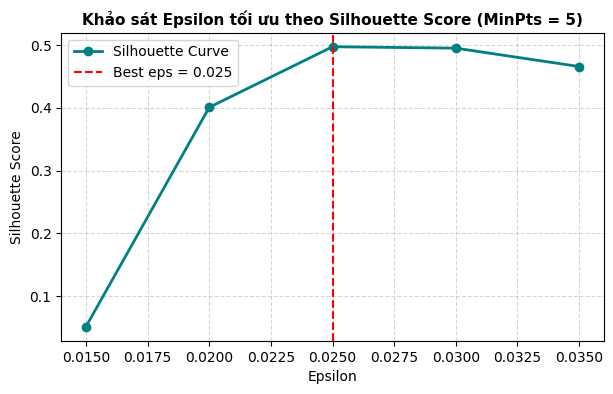

In [3]:
# 3. Quét dải Epsilon từ 0.015 đến 0.075 (MinPts = 5) để tìm Epsilon tối ưu
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score

eps_range = np.arange(0.015, 0.080, 0.005)
records = []

for eps in eps_range:
    labels = DBSCAN(eps=eps, min_samples=5).fit_predict(data_scaled[['Fresh', 'Milk']])
    n_clusters = len(set(labels) - {-1})
    n_noise = (labels == -1).sum()
    
    if n_clusters >= 2:
        mask = (labels != -1)
        score = silhouette_score(data_scaled.loc[mask, ['Fresh', 'Milk']], labels[mask])
        records.append({'Epsilon': round(eps, 3), 'Số cụm': n_clusters, 'Số ngoại lai': n_noise, 'Silhouette Score': round(score, 4)})
    else:
        records.append({'Epsilon': round(eps, 3), 'Số cụm': n_clusters, 'Số ngoại lai': n_noise, 'Silhouette Score': np.nan})

df_eval = pd.DataFrame(records)
best_eps = df_eval.loc[df_eval['Silhouette Score'].idxmax(), 'Epsilon']
best_score = df_eval['Silhouette Score'].max()

print(f"=> Epsilon tối ưu nhất: {best_eps} với Silhouette Score = {best_score:.4f}")

# Vẽ đồ thị đường biểu diễn Silhouette Score theo Epsilon
plt.figure(figsize=(7, 4))
plt.plot(df_eval['Epsilon'], df_eval['Silhouette Score'], marker='o', color='teal', linewidth=2, label='Silhouette Curve')
plt.axvline(x=best_eps, color='red', linestyle='--', label=f'Best eps = {best_eps}')
plt.title('Khảo sát Epsilon tối ưu theo Silhouette Score (MinPts = 5)', fontsize=11, fontweight='bold')
plt.xlabel('Epsilon')
plt.ylabel('Silhouette Score')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

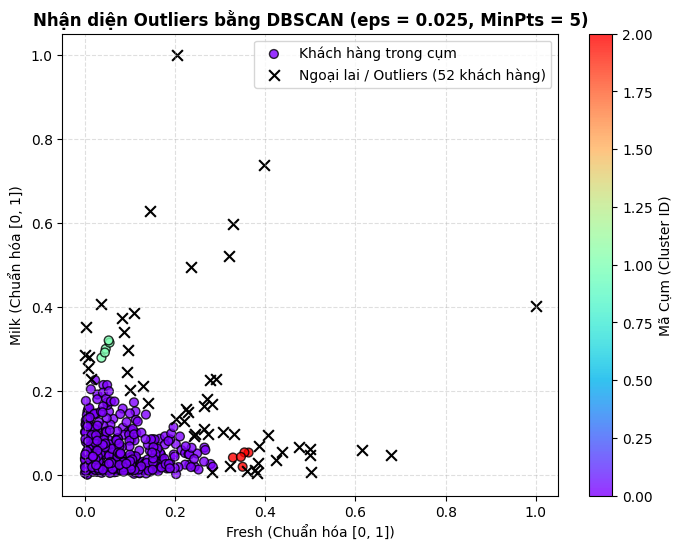

In [4]:
# 4. Huấn luyện DBSCAN với Epsilon tối ưu và trực quan hóa nhận diện Outliers
dbscan_model = DBSCAN(eps=best_eps, min_samples=5)
data_scaled['Cluster'] = dbscan_model.fit_predict(data_scaled[['Fresh', 'Milk']])
df['Cluster'] = data_scaled['Cluster'].values

plt.figure(figsize=(8, 6))

# 1. Vẽ các điểm khách hàng thuộc cụm (Cluster >= 0) bằng các màu khác nhau
clustered = data_scaled[data_scaled['Cluster'] != -1]
scatter = plt.scatter(
    clustered['Fresh'], 
    clustered['Milk'], 
    c=clustered['Cluster'], 
    cmap='rainbow', 
    s=40,
    alpha=0.8,
    edgecolor='k',
    label='Khách hàng trong cụm'
)

# 2. Vẽ các điểm Ngoại lai (Outliers / Nhiễu == -1) bằng dấu 'x' màu đen nổi bật
outliers = data_scaled[data_scaled['Cluster'] == -1]
plt.scatter(
    outliers['Fresh'], 
    outliers['Milk'], 
    color='black', 
    marker='x', 
    s=60, 
    linewidths=1.5,
    label=f'Ngoại lai / Outliers ({len(outliers)} khách hàng)'
)

plt.title(f'Nhận diện Outliers bằng DBSCAN (eps = {best_eps}, MinPts = 5)', fontsize=12, fontweight='bold')
plt.xlabel('Fresh (Chuẩn hóa [0, 1])', fontsize=10)
plt.ylabel('Milk (Chuẩn hóa [0, 1])', fontsize=10)
plt.colorbar(scatter, label='Mã Cụm (Cluster ID)')
plt.grid(True, linestyle='--', alpha=0.4)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

In [5]:
# 5. Phân tích chi tiết danh sách khách hàng Outlier và so sánh mức chi tiêu thực tế
outliers_df = df[df['Cluster'] == -1]

print(f"Tổng số khách hàng Outlier: {len(outliers_df)} / {len(df)} ({len(outliers_df)/len(df)*100:.1f}%)\n")

print("=== 10 KHÁCH HÀNG OUTLIER TIÊU BIỂU (Chi tiêu gốc) ===")
print(outliers_df[['Fresh', 'Milk']].head(10))

print("\n=== SO SÁNH CHI TIÊU TRUNG BÌNH (Đơn vị tiền tệ m.u.) ===")
summary = df.groupby(df['Cluster'] == -1)[['Fresh', 'Milk']].mean().rename(
    index={False: 'Nhóm khách hàng thông thường (Cụm 0, 1, 2)', True: 'Nhóm khách hàng Outliers / VIP (-1)'}
)
print(summary.round(1))

Tổng số khách hàng Outlier: 52 / 440 (11.8%)

=== 10 KHÁCH HÀNG OUTLIER TIÊU BIỂU (Chi tiêu gốc) ===
    Fresh   Milk
12  31714  12319
14  24653   9465
23  26373  36423
24  22647   9776
29  43088   2100
39  56159    555
47  44466  54259
56   4098  29892
61  35942  38369
65     85  20959

=== SO SÁNH CHI TIÊU TRUNG BÌNH (Đơn vị tiền tệ m.u.) ===
                                              Fresh     Milk
Cluster                                                     
Nhóm khách hàng thông thường (Cụm 0, 1, 2)   9423.5   4455.9
Nhóm khách hàng Outliers / VIP (-1)         31227.2  15797.2
